# 04 — Small MLP (PyTorch, CPU), validation only

**Design**
* Input: 2,000 HVGs, z-scored. HVG selection and scaling are fit on training cells only (same pipeline
  and split as Phase 3).
* Output: all 134 proteins. Targets are standardized per protein with the training mean/SD, so each
  protein weighs equally in the MSE loss. Predictions are mapped back to the CLR scale.
* Architecture: Linear -> ReLU -> Dropout blocks, AdamW, batch 512, lr 1e-3, at most 200 epochs.
  **Early stopping on validation loss** (patience 15); the best-epoch weights are kept.
* Search (seed 0): hidden layers {[256], [512, 256], [1024, 512]} x dropout {0.1, 0.3} x weight decay
  {1e-4, 1e-2}. The best configuration is chosen by the same metric as in Phase 3: mean validation
  Pearson over all 134 proteins. If the best value is on a grid edge, the grid is extended (validation
  only) and the extension is logged. Exception: the first hidden layer is capped at 2,048 units for CPU
  time. If the cap is hit, this is logged as well.
* The best configuration is trained with **3 seeds** (0, 1, 2), and results are reported as mean ± SD.
* Checkpoints go to `data/processed/phase4_checkpoints/`. A finished run is re-used if the notebook is
  run again.
* **Test cells are not used.** Validation decides both early stopping and the configuration, and the MLP
  search space is larger than ridge's. The MLP's validation numbers are therefore likely to be somewhat
  more optimistic than ridge's.
* Metrics as in Phase 3, plus within cell type x sample (notebook 03b).

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from citeseq.paths import RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from citeseq.data_prep import load_train_val
from citeseq.baselines import HVGPCAFeatures, RidgePath
from citeseq.correlation import pearson_columns
from citeseq.metrics import evaluate
from citeseq.mlp import TargetScaler, train_mlp, predict
from citeseq import plotting as P

torch.set_num_threads(8)
SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
MAX_EPOCHS = int(os.environ.get("CITESEQ_MAX_EPOCHS", 200))
PATIENCE = 15
HIDDEN = [[256], [512, 256], [1024, 512]]
DROPOUT = [0.1, 0.3]
WEIGHT_DECAY = [1e-4, 1e-2]
SEEDS = [0, 1, 2]
MIN_CELLS = 50
MAX_EXPANSIONS = 3
MAX_WIDTH = 2048          # compute cap for the first hidden layer (CPU time)
cfg3 = json.loads((RESULTS_DIR / "phase3_frozen_configs.json").read_text())
CKPT = PROCESSED_DIR / ("phase4_checkpoints" if SUBSET is None else "test_phase4_checkpoints")
OUT_FIG = FIGURES_DIR if SUBSET is None else PROCESSED_DIR / "test_figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)
P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
print("subset:", SUBSET, "| max epochs:", MAX_EPOCHS, "| torch", torch.__version__, "threads", torch.get_num_threads())

subset: None | max epochs: 200 | torch 2.2.2 threads 8


## 1. Inputs (train-only pipeline, same split as Phase 3)

In [2]:
t0 = time.time()
d = load_train_val(RESULTS_DIR / "splits/random_split.csv.gz", subset=SUBSET)
proteins, pmap = d["proteins"], d["pmap"]
primary = pmap.index[pmap["analysis_set"] == "primary"].tolist()
feats = HVGPCAFeatures(n_top_genes=cfg3["features"]["hvg"], max_pcs=None, seed=cfg3["seed"]).fit(
    d["X_tr"], d["obs_tr"], d["gene_names"])
H_tr, H_va = feats.transform_hvg(d["X_tr"]), feats.transform_hvg(d["X_va"])
Y_tr, Y_va = d["Y_tr"], d["Y_va"]
ys = TargetScaler().fit(Y_tr)
Z_tr, Z_va = ys.transform(Y_tr), ys.transform(Y_va)
ct_va = d["obs_va"]["cell_type"].astype(str).to_numpy()
ts_va = (d["obs_va"]["cell_type"].astype(str) + " | " + d["obs_va"]["batch"].astype(str)).to_numpy()
print(f"inputs in {time.time() - t0:.0f}s | train {H_tr.shape} | val {H_va.shape} | test cells not loaded: {d['n_test']}")

# Ridge reference: the frozen Phase 3 model 3a (full-rank PCA)
n3a, a3a = cfg3["3a_ridge_pca"]["n_pcs"], cfg3["3a_ridge_pca"]["alpha"]
P_tr, P_va = feats.transform_pca(d["X_tr"], n3a), feats.transform_pca(d["X_va"], n3a)
pred_ridge = RidgePath().fit(P_tr, Y_tr, [a3a]).predict(P_va, a3a)
del P_tr, P_va
def sel_metric(p):
    return float(np.nanmean(pearson_columns(p, Y_va)))
print("ridge 3a selection metric:", round(sel_metric(pred_ridge), 4))

inputs in 30s | train (63182, 2000) | val (13539, 2000) | test cells not loaded: 13540


ridge 3a selection metric: 0.6818


## 2. Search (seed 0)

In [3]:
def ckpt_path(hidden, dropout, wd, seed):
    key = json.dumps([hidden, dropout, wd, seed, MAX_EPOCHS, PATIENCE])
    return CKPT / f"mlp_{hashlib.md5(key.encode()).hexdigest()[:10]}.pt"

runs = {}
def run(hidden, dropout, wd, seed):
    k = (tuple(hidden), dropout, wd, seed)
    if k in runs:
        return runs[k]
    t = time.time()
    out = train_mlp(H_tr, Z_tr, H_va, Z_va, hidden=hidden, dropout=dropout, weight_decay=wd, seed=seed,
                    max_epochs=MAX_EPOCHS, patience=PATIENCE, checkpoint=ckpt_path(hidden, dropout, wd, seed))
    p = predict(out["model"], H_va, ys)
    runs[k] = dict(hidden=str(hidden), dropout=dropout, weight_decay=wd, seed=seed, pred=p,
                   val_mean_pearson=sel_metric(p), best_epoch=out["best_epoch"],
                   epochs_run=len(out["history"]["val_loss"]), history=out["history"],
                   minutes=(time.time() - t) / 60, loaded=out["loaded"])
    r = runs[k]
    print(f"{str(hidden):<12} drop {dropout:<4} wd {wd:<7g} seed {seed}: val mean r {r['val_mean_pearson']:.4f}, "
          f"best epoch {r['best_epoch']}, {r['epochs_run']} epochs, {r['minutes']:.1f} min{' (loaded)' if r['loaded'] else ''}")
    return r

t0 = time.time()
hidden_grid, drop_grid, wd_grid = [list(h) for h in HIDDEN], list(DROPOUT), list(WEIGHT_DECAY)
for h in hidden_grid:
    for dr in drop_grid:
        for wd in wd_grid:
            run(h, dr, wd, 0)
expansion_log = []
def search_table():
    return pd.DataFrame([{k: v for k, v in r.items() if k not in ("pred", "history")} for r in runs.values() if r["seed"] == 0])
for _ in range(MAX_EXPANSIONS):
    st = search_table()
    b = st.loc[st["val_mean_pearson"].idxmax()]
    hb, drb, wdb = eval(b["hidden"]), float(b["dropout"]), float(b["weight_decay"])
    new = []
    if hb == hidden_grid[-1]:
        h2 = [2 * x for x in hidden_grid[-1]]
        if h2[0] <= MAX_WIDTH:
            hidden_grid.append(h2); new.append(("hidden", h2))
        elif not any("compute cap" in e for e in expansion_log):
            expansion_log.append(f"best hidden {hb} is the largest allowed; not extended to {h2} (compute cap {MAX_WIDTH})")
    elif hb == hidden_grid[0]:
        h2 = [max(32, x // 2) for x in hidden_grid[0]]; hidden_grid.insert(0, h2); new.append(("hidden", h2))
    if drb == max(drop_grid) and drb < 0.6:
        drop_grid.append(round(drb + 0.2, 2)); new.append(("dropout", drop_grid[-1]))
    elif drb == min(drop_grid) and drb > 0:
        drop_grid.insert(0, 0.0); new.append(("dropout", 0.0))
    if wdb == max(wd_grid):
        wd_grid.append(wdb * 10); new.append(("weight_decay", wd_grid[-1]))
    elif wdb == min(wd_grid):
        wd_grid.insert(0, wdb / 10); new.append(("weight_decay", wd_grid[0]))
    if not new:
        break
    expansion_log.append(f"best {hb}, dropout {drb}, wd {wdb:g} on a grid edge -> added {new}")
    # evaluate the new values around the current best (one dimension at a time)
    for kind, v in new:
        if kind == "hidden":
            run(v, drb, wdb, 0)
        elif kind == "dropout":
            run(hb, v, wdb, 0)
        else:
            run(hb, drb, v, 0)
print(f"search: {(time.time() - t0) / 60:.1f} min")
print("grid extensions (validation only):", expansion_log or "none")
search = search_table().sort_values("val_mean_pearson", ascending=False)
search

[256]        drop 0.1  wd 0.0001  seed 0: val mean r 0.7106, best epoch 5, 21 epochs, 0.3 min


[256]        drop 0.1  wd 0.01    seed 0: val mean r 0.7105, best epoch 5, 21 epochs, 0.3 min


[256]        drop 0.3  wd 0.0001  seed 0: val mean r 0.7148, best epoch 21, 37 epochs, 0.5 min


[256]        drop 0.3  wd 0.01    seed 0: val mean r 0.7147, best epoch 21, 37 epochs, 0.5 min


[512, 256]   drop 0.1  wd 0.0001  seed 0: val mean r 0.7302, best epoch 9, 25 epochs, 0.8 min


[512, 256]   drop 0.1  wd 0.01    seed 0: val mean r 0.7302, best epoch 9, 25 epochs, 0.8 min


... (6 outputs left out)

[2048, 1024] drop 0.3  wd 0.0001  seed 0: val mean r 0.7332, best epoch 11, 27 epochs, 4.2 min


[1024, 512]  drop 0.5  wd 0.0001  seed 0: val mean r 0.7323, best epoch 38, 54 epochs, 3.3 min


[1024, 512]  drop 0.3  wd 1e-05   seed 0: val mean r 0.7349, best epoch 30, 46 epochs, 2.5 min
search: 21.7 min
grid extensions (validation only): ["best [1024, 512], dropout 0.3, wd 0.0001 on a grid edge -> added [('hidden', [2048, 1024]), ('dropout', 0.5), ('weight_decay', 1e-05)]"]


,hidden,dropout,weight_decay,seed,val_mean_pearson,best_epoch,epochs_run,minutes,loaded
10,"[1024, 512]",0.300,0.000,0,0.735,15,31,1.743,False
11,"[1024, 512]",0.300,0.010,0,0.735,16,32,1.930,False
14,"[1024, 512]",0.300,0.000,0,0.735,30,46,2.494,False
7,"[512, 256]",0.300,0.010,0,0.734,25,41,1.164,False
12,"[2048, 1024]",0.300,0.000,0,0.733,11,27,4.196,False
6,"[512, 256]",0.300,0.000,0,0.733,28,44,1.550,False
8,"[1024, 512]",0.100,0.000,0,0.733,4,20,1.189,False
13,"[1024, 512]",0.500,0.000,0,0.732,38,54,3.252,False
9,"[1024, 512]",0.100,0.010,0,0.732,3,19,1.048,False
5,"[512, 256]",0.100,0.010,0,0.730,9,25,0.751,False


## 3. Best configuration with 3 seeds

In [4]:
best = search.iloc[0]
best_cfg = dict(hidden=eval(best["hidden"]), dropout=float(best["dropout"]), weight_decay=float(best["weight_decay"]))
print("best configuration:", best_cfg)
final = [run(best_cfg["hidden"], best_cfg["dropout"], best_cfg["weight_decay"], s) for s in SEEDS]

best configuration: {'hidden': [1024, 512], 'dropout': 0.3, 'weight_decay': 0.0001}


[1024, 512]  drop 0.3  wd 0.0001  seed 1: val mean r 0.7349, best epoch 21, 37 epochs, 1.9 min


[1024, 512]  drop 0.3  wd 0.0001  seed 2: val mean r 0.7354, best epoch 18, 34 epochs, 1.8 min


### Would the within cell type x sample metric pick a different configuration?

Selection stays with the pre-specified metric (overall Pearson). This only reports whether ranking the
seed-0 search runs by within cell type x sample Pearson (primary set, median) would point elsewhere.

In [5]:
ts_rows = []
for r in runs.values():
    if r["seed"] != 0:
        continue
    e = evaluate(Y_va, r["pred"], ts_va, proteins, MIN_CELLS).loc[primary]
    ts_rows.append({"hidden": r["hidden"], "dropout": r["dropout"], "weight_decay": r["weight_decay"],
                    "val_mean_pearson": r["val_mean_pearson"], "within_type_sample_w": e["within_w"].median()})
ts_rank = pd.DataFrame(ts_rows).sort_values("within_type_sample_w", ascending=False)
b_ts = ts_rank.iloc[0]
same_cfg = (b_ts["hidden"] == best["hidden"] and b_ts["dropout"] == best["dropout"]
            and b_ts["weight_decay"] == best["weight_decay"])
print("best by overall Pearson (selected):", best_cfg)
print("best by within type x sample      :", {"hidden": b_ts["hidden"], "dropout": b_ts["dropout"], "weight_decay": b_ts["weight_decay"]},
      "| same configuration:", same_cfg)
ts_rank

best by overall Pearson (selected): {'hidden': [1024, 512], 'dropout': 0.3, 'weight_decay': 0.0001}
best by within type x sample      : {'hidden': '[512, 256]', 'dropout': 0.1, 'weight_decay': 0.01} | same configuration: False


,hidden,dropout,weight_decay,val_mean_pearson,within_type_sample_w
5,"[512, 256]",0.100,0.010,0.730,0.114
8,"[1024, 512]",0.100,0.000,0.733,0.114
9,"[1024, 512]",0.100,0.010,0.732,0.114
4,"[512, 256]",0.100,0.000,0.730,0.114
10,"[1024, 512]",0.300,0.000,0.735,0.114
7,"[512, 256]",0.300,0.010,0.734,0.113
11,"[1024, 512]",0.300,0.010,0.735,0.113
12,"[2048, 1024]",0.300,0.000,0.733,0.112
13,"[1024, 512]",0.500,0.000,0.732,0.111
14,"[1024, 512]",0.300,0.000,0.735,0.109


In [6]:
def summarize(p):
    e_t = evaluate(Y_va, p, ct_va, proteins, MIN_CELLS)
    e_ts = evaluate(Y_va, p, ts_va, proteins, MIN_CELLS)
    e_t["within_type_sample_w"] = e_ts["within_w"]
    return e_t

per_seed = {s: summarize(r["pred"]) for s, r in zip(SEEDS, final)}
ridge_eval = summarize(pred_ridge)
metrics = ["pearson_all", "within_w", "within_unw", "within_type_sample_w", "rmse"]
seed_medians = pd.DataFrame({s: e.loc[primary, metrics].median() for s, e in per_seed.items()}).T
tab = pd.DataFrame({
    "MLP mean": seed_medians.mean(), "MLP SD (3 seeds)": seed_medians.std(ddof=1),
    "ridge 3a (Phase 3)": ridge_eval.loc[primary, metrics].median(),
})
tab["MLP - ridge"] = tab["MLP mean"] - tab["ridge 3a (Phase 3)"]
print(f"PRIMARY set ({len(primary)} proteins), validation; median across proteins per seed, then mean ± SD over seeds")
tab

PRIMARY set (110 proteins), validation; median across proteins per seed, then mean ± SD over seeds


,MLP mean,MLP SD (3 seeds),ridge 3a (Phase 3),MLP - ridge
pearson_all,0.794,0.001,0.733,0.061
within_w,0.446,0.000,0.337,0.109
within_unw,0.427,0.000,0.326,0.101
within_type_sample_w,0.114,0.003,0.104,0.010
rmse,0.289,0.001,0.312,-0.023


In [7]:
# Per protein: MLP (mean over seeds) vs ridge
mlp_pp = sum(per_seed[s][metrics] for s in SEEDS) / len(SEEDS)
for m in ["pearson_all", "within_w", "within_type_sample_w"]:
    dlt = (mlp_pp.loc[primary, m] - ridge_eval.loc[primary, m])
    print(f"{m:<22} MLP - ridge: median {dlt.median():+.3f}; MLP better for {(dlt > 0).sum()} of {dlt.notna().sum()}")
for name, sel in [("secondary", "secondary"), ("unavailable", "unavailable")]:
    prots = pmap.index[pmap["analysis_set"] == sel].tolist()
    print(f"{name:<11} set: MLP pearson_all {mlp_pp.loc[prots, 'pearson_all'].median():.3f} vs ridge {ridge_eval.loc[prots, 'pearson_all'].median():.3f}; "
          f"within {mlp_pp.loc[prots, 'within_w'].median():.3f} vs {ridge_eval.loc[prots, 'within_w'].median():.3f}")

pearson_all            MLP - ridge: median +0.048; MLP better for 110 of 110
within_w               MLP - ridge: median +0.100; MLP better for 110 of 110
within_type_sample_w   MLP - ridge: median +0.014; MLP better for 94 of 110
secondary   set: MLP pearson_all 0.889 vs ridge 0.856; within 0.453 vs 0.378
unavailable set: MLP pearson_all 0.533 vs ridge 0.466; within 0.308 vs 0.247


## 4. Training curves

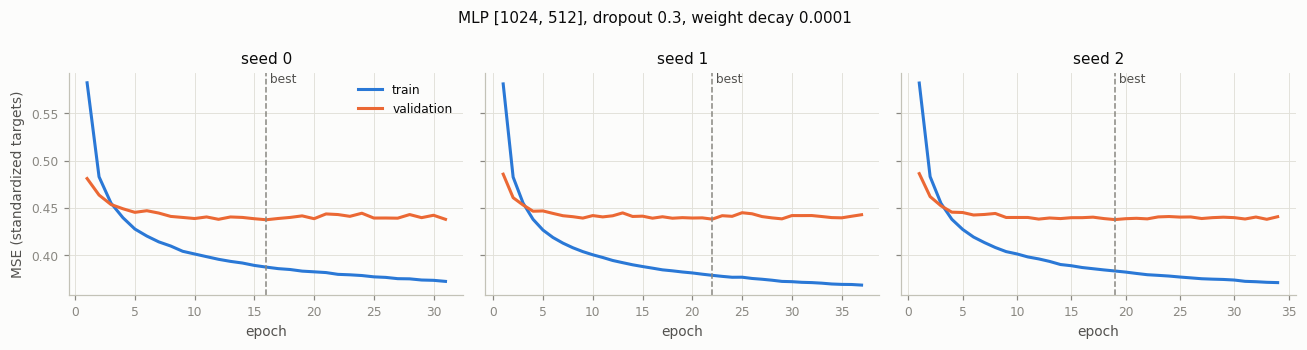

In [8]:
fig, axes = plt.subplots(1, len(final), figsize=(4 * len(final), 3.2), sharey=True)
for ax, r in zip(np.atleast_1d(axes), final):
    h = r["history"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], color=P.BLUE, lw=2, label="train")
    ax.plot(ep, h["val_loss"], color=P.ORANGE, lw=2, label="validation")
    ax.axvline(r["best_epoch"] + 1, color=P.MUTED, ls="--", lw=1)
    ax.text(r["best_epoch"] + 1, ax.get_ylim()[1], " best", va="top", fontsize=8, color=P.INK_2)
    ax.set_title(f"seed {r['seed']}"); ax.set_xlabel("epoch")
np.atleast_1d(axes)[0].set_ylabel("MSE (standardized targets)")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"MLP {best_cfg['hidden']}, dropout {best_cfg['dropout']}, weight decay {best_cfg['weight_decay']:g}", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase4_training_curves.png")

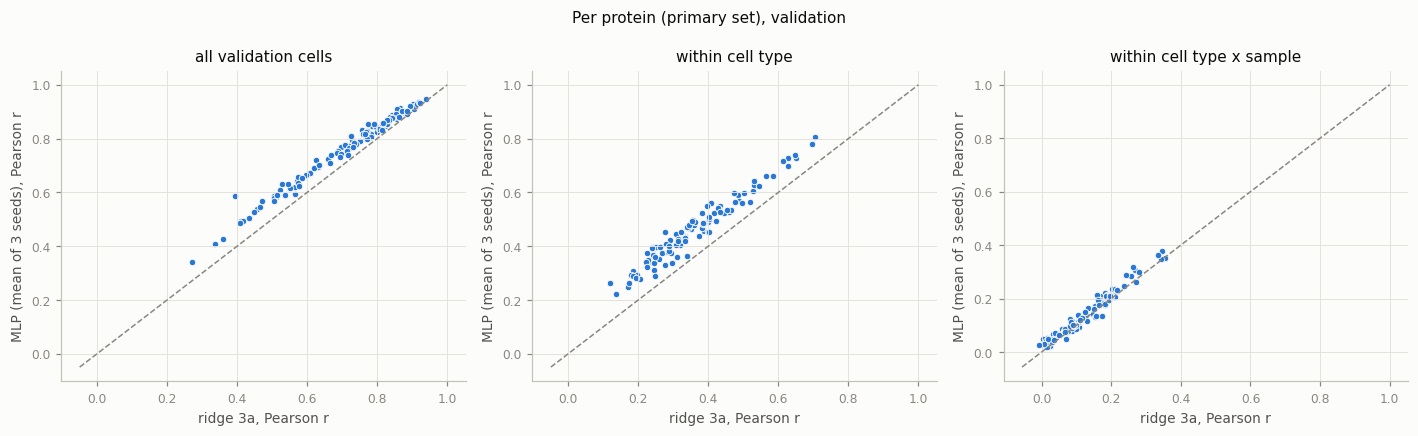

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, m, title in zip(axes, ["pearson_all", "within_w", "within_type_sample_w"],
                        ["all validation cells", "within cell type", "within cell type x sample"]):
    x, y = ridge_eval.loc[primary, m], mlp_pp.loc[primary, m]
    lo = min(np.nanmin(x), np.nanmin(y), 0) - 0.05
    ax.plot([lo, 1], [lo, 1], color=P.MUTED, ls="--", lw=1)
    ax.scatter(x, y, s=18, c=P.BLUE, edgecolors=P.SURFACE, linewidths=0.6)
    ax.set_xlabel("ridge 3a, Pearson r"); ax.set_ylabel("MLP (mean of 3 seeds), Pearson r"); ax.set_title(title)
fig.suptitle("Per protein (primary set), validation", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase4_mlp_vs_ridge.png")

In [10]:
frozen = {
    "split_file": "results/splits/random_split.csv.gz", "input": "2000 HVGs, z-scored (train-only)",
    "targets": "per-protein standardized CLR (train mean/SD)",
    "selection_metric": "mean validation Pearson over all 134 proteins (best-epoch weights)",
    "early_stopping": {"monitor": "validation MSE", "patience": PATIENCE, "max_epochs": MAX_EPOCHS},
    "grid": {"hidden": hidden_grid, "dropout": drop_grid, "weight_decay": wd_grid},
    "grid_extensions_based_on_validation": expansion_log,
    "hidden_width_cap": MAX_WIDTH,
    "best": {**best_cfg, "lr": 1e-3, "batch_size": 512, "optimizer": "AdamW"},
    "seeds": SEEDS, "best_epochs": [r["best_epoch"] for r in final],
    "best_by_within_type_sample_seed0": {"hidden": b_ts["hidden"], "dropout": float(b_ts["dropout"]),
                                         "weight_decay": float(b_ts["weight_decay"]), "same_as_selected": bool(same_cfg)},
}
if SUBSET is None:
    (RESULTS_DIR / "phase4_frozen_config.json").write_text(json.dumps(frozen, indent=2))
    search.merge(ts_rank[["hidden", "dropout", "weight_decay", "within_type_sample_w"]],
                 on=["hidden", "dropout", "weight_decay"], how="left").to_csv(RESULTS_DIR / "phase4_search.csv", index=False)
    pd.concat({f"seed{s}": e.assign(analysis_set=pmap["analysis_set"]) for s, e in per_seed.items()},
              names=["seed"]).reset_index().to_csv(RESULTS_DIR / "phase4_val_per_protein.csv", index=False)
    np.savez_compressed(PROCESSED_DIR / "phase4_val_predictions.npz", proteins=np.array(proteins),
                        **{f"mlp_seed{r['seed']}": r["pred"].astype(np.float32) for r in final})
frozen

{'split_file': 'results/splits/random_split.csv.gz',
 'input': '2000 HVGs, z-scored (train-only)',
 'targets': 'per-protein standardized CLR (train mean/SD)',
 'selection_metric': 'mean validation Pearson over all 134 proteins (best-epoch weights)',
 'early_stopping': {'monitor': 'validation MSE',
  'patience': 15,
  'max_epochs': 200},
 'grid': {'hidden': [[256], [512, 256], [1024, 512], [2048, 1024]],
  'dropout': [0.1, 0.3, 0.5],
  'weight_decay': [1e-05, 0.0001, 0.01]},
 'grid_extensions_based_on_validation': ["best [1024, 512], dropout 0.3, wd 0.0001 on a grid edge -> added [('hidden', [2048, 1024]), ('dropout', 0.5), ('weight_decay', 1e-05)]"],
 'hidden_width_cap': 2048,
 'best': {'hidden': [1024, 512],
  'dropout': 0.3,
  'weight_decay': 0.0001,
  'lr': 0.001,
  'batch_size': 512,
  'optimizer': 'AdamW'},
 'seeds': [0, 1, 2],
 'best_epochs': [15, 21, 18],
 'best_by_within_type_sample_seed0': {'hidden': '[512, 256]',
  'dropout': 0.1,
  'weight_decay': 0.01,
  'same_as_selected':

In [11]:
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
print(f"peak memory: {(peak / 1e9 if platform.system() == 'Darwin' else peak * 1024 / 1e9):.2f} GB")

peak memory: 3.62 GB


## Findings (full data, **validation only**: test cells were not evaluated)

**Search** (seed 0, 15 runs, 22 min).
* The best configuration is [1024, 512], dropout 0.3, weight decay 1e-4 (mean validation Pearson 0.735).
* It sat on three grid edges, so the grid was extended once (logged): [2048, 1024], dropout 0.5,
  weight decay 1e-5. None of these was better.
* The width cap (2,048) was not binding.
* Weight decay barely matters here: 1e-5, 1e-4 and 1e-2 all give 0.735.
* Ranking by within cell type x sample instead would pick [512, 256], dropout 0.1, wd 0.01 (0.1140
  vs 0.1135 for the selected configuration). The difference of 0.0005 is far below the seed SD
  (0.003), so this is effectively a tie.

**Training curves.** Validation loss flattens after about 5-10 epochs while training loss keeps falling.
Early stopping picked epochs 15, 21 and 18 for the three seeds. Because the validation curve is nearly
flat, the exact best epoch is not well determined, but it hardly matters for the loss.

**Primary set (110 proteins), validation; median over proteins per seed, then mean ± SD over 3 seeds**

| | MLP | ridge 3a | MLP - ridge |
|---|---|---|---|
| Pearson, all cells | 0.794 ± 0.001 | 0.733 | +0.061 |
| within cell type (weighted) | 0.446 ± 0.000 | 0.337 | +0.109 |
| within cell type x sample | 0.114 ± 0.003 | 0.104 | +0.010 |
| RMSE | 0.289 ± 0.001 | 0.312 | -0.023 |

* The MLP is better than ridge for all 110 proteins overall and within cell type, and for 94 of 110
  within cell type x sample.
* **Most of the MLP's within-type gain is at the sample level.** Within type it gains +0.11 over ridge,
  but within type x sample only +0.01. Using the same heuristic split as in 03b, the MLP's 0.45 is
  roughly 0.33 between samples and 0.11 within samples (ridge: 0.23 and 0.10).
* This is exactly the component that Phase 5 tests for transfer to unseen samples. The MLP's validation
  advantage may therefore shrink on unseen sites. This is a hypothesis.
* Seed-to-seed SD is <= 0.003 for every metric. This supports using 1 MLP seed per fold in Phase 5.
* Other sets: secondary 0.89 vs 0.86 overall; the 17 proteins without a measured gene 0.53 vs 0.47
  overall and 0.31 vs 0.25 within type.
* These numbers are more optimistic than ridge's: validation chose the architecture, the regularization
  and the stopping epoch.

Peak memory 3.6 GB; total runtime 26 min.